# LinkedIn Job Market: ETL + Analytics Pipeline

One notebook that connects every module: **scrape → clean → load into MySQL → verify → analyse → export for Power BI**.

```text
linkedin-job-etl/
├── linkedin_job_etl_pipeline.ipynb   <- this notebook
├── config.py          settings, skill regexes, DB credentials (via .env)
├── scraper.py         Extract: LinkedIn guest endpoints
├── cleaner.py         Transform: roles, location, skills, experience, work mode
├── db_loader.py       Load: MySQL / SQL Server / SQLite, views, run log
├── analysis_utils.py  Data access + skill analytics used below
├── demo_data.py       SYNTHETIC data so the analysis runs before you scrape
├── main.py            Same pipeline from the command line
├── .env               your DB password (copy from .env.example, never commit)
└── data_backups/ , powerbi_exports/   created automatically
```
The flow is safe to re-run: jobs already in the database are skipped **before** their detail pages are requested.

## 1. Install packages (run once, then restart the kernel)

In [1]:
# %pip install requests beautifulsoup4 pandas numpy sqlalchemy mysql-connector-python python-dotenv plotly

In [2]:
import os, getpass
os.environ["DB_PASSWORD"] = getpass.getpass("MySQL root password: ")

MySQL root password:  ········


## 2. Verify project files and import the modules

In [5]:
import os, sys, logging, importlib
from datetime import datetime
import pandas as pd

PROJECT_DIR = os.getcwd()
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

required = ["config.py", "scraper.py", "cleaner.py", "db_loader.py",
            "analysis_utils.py", "demo_data.py", "main.py"]
missing = [f for f in required if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f"Missing {missing} in {PROJECT_DIR}. Put this notebook in the same folder as the .py files.")

logging.basicConfig(level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)-8s | %(name)s | %(message)s")
logger = logging.getLogger("Notebook_ETL")

import config, scraper, cleaner, db_loader, demo_data, analysis_utils
for module in (config, scraper, cleaner, db_loader, demo_data, analysis_utils):
    importlib.reload(module)          # picks up edits to the .py files without restarting

pd.set_option("display.max_columns", 40, "display.width", 200)
logger.info("All modules imported.")

2026-11-20 20:06:27,184 | INFO     | Notebook_ETL | All modules imported.


## 3. Run settings
Everything you normally change lives in this one cell. The defaults are a **small test run** (3 keywords, 1 page each) because LinkedIn rate-limits (HTTP 429) quickly. Increase `RUN_PAGES` once it works.

In [6]:
# ---- what to scrape -------------------------------------------------------
RUN_KEYWORDS  = config.SEARCH_KEYWORDS[:3]     # e.g. ["Data Analyst", "SQL Developer"]
RUN_LOCATIONS = config.SEARCH_LOCATIONS        # e.g. ["Mumbai", "Pune"]
RUN_PAGES     = 1                              # ~10 jobs per page
DATE_POSTED   = config.DATE_POSTED             # "24h" | "week" | "month" | None

# ---- which steps to run ---------------------------------------------------
RUN_SCRAPER = True     # False = do not scrape (analyse what is already stored)
RAW_CSV     = None     # e.g. "data_backups/raw_20261118_204441.csv" = re-clean a saved scrape, no scraping
USE_DB      = True     # False = CSV only, no database

# ---- analysis settings ----------------------------------------------------
DATA_SOURCE = "auto"                           # "db" | "csv" | "demo" | "auto" (db -> latest csv -> demo)
MY_SKILLS   = ["Excel", "SQL", "Python", "Power_BI", "Data_Viz"]   # keys from config.SKILL_PATTERNS: edit to match you

show_keys = {"mysql": ["host", "port", "user", "password", "database"],
             "sqlserver": ["server", "database", "driver", "trusted_connection"]}.get(config.DB_BACKEND, [])
safe_db = {k: ("***" if k == "password" else config.DB_CONFIG[k]) for k in show_keys}
print("Backend      :", config.DB_BACKEND)
print("DB target    :", safe_db or config.SQLITE_PATH)
print("Keywords     :", RUN_KEYWORDS)
print("Locations    :", RUN_LOCATIONS, "| pages:", RUN_PAGES, "| posted:", DATE_POSTED)

Backend      : mysql
DB target    : {'host': 'localhost', 'port': 3306, 'user': 'root', 'password': '***', 'database': 'JobMarketAnalytics'}
Keywords     : ['Data Analyst', 'Business Analyst', 'BI Developer']
Locations    : ['Mumbai'] | pages: 1 | posted: week


In [7]:
import config
print("project folder :", config.BASE_DIR)
print(".env exists    :", (config.BASE_DIR / ".env").exists())
print("password set   :", bool(config.DB_CONFIG["password"]))
try:
    import dotenv; print("python-dotenv  : installed")
except ImportError:
    print("python-dotenv  : MISSING -> run  %pip install python-dotenv")

project folder : C:\Users\Admin\Desktop\Data projects\New folder\linkedin-job-etl
.env exists    : False
password set   : True
python-dotenv  : MISSING -> run  %pip install python-dotenv


## 4. Step 0: Connect to the database
Creates the database/tables if needed, adds any new columns to your **existing** table, and loads the IDs you already have so they are not scraped again.
If the connection fails, the notebook carries on without the database and tells you what to fix.

In [8]:
engine, run_id, existing_ids = None, None, set()

if USE_DB:
    try:
        engine = db_loader.get_db_engine()
        ok, msg = db_loader.check_connection(engine)
    except Exception as exc:                      # e.g. driver package not installed
        ok, msg = False, f"{type(exc).__name__}: {exc}"
    print(msg)

    if ok:
        db_loader.initialize_database(engine)
        existing_ids = db_loader.get_existing_job_ids(engine)
        run_id = db_loader.log_run_start(engine)
        print(f"{len(existing_ids)} jobs already stored in '{config.JOBS_TABLE}'.")
    else:
        print("\n-> Continuing WITHOUT the database. Check DB_USER / DB_PASSWORD / DB_HOST in your .env, "
              "that MySQL is running, and that mysql-connector-python is installed.\n"
              "   Quick alternative: set DB_BACKEND=sqlite in .env.  Then re-run this cell.")
        USE_DB, engine = False, None

2026-11-20 20:06:34,529 | INFO     | db_loader | Database ready (mysql).


Connected (mysql).
0 jobs already stored in 'fact_linkedin_jobs'.


## 5. Step 1: Extract (`scraper.py`)

In [9]:
raw_df = pd.DataFrame()
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
config.BACKUP_DIR.mkdir(exist_ok=True)

if RAW_CSV:
    raw_df = pd.read_csv(RAW_CSV, encoding="utf-8-sig", dtype={"job_id": str})
    print(f"Loaded {len(raw_df)} raw rows from {RAW_CSV}")
elif RUN_SCRAPER:
    raw_df = scraper.scrape_linkedin_jobs(RUN_KEYWORDS, RUN_LOCATIONS, RUN_PAGES,
                                          existing_ids=existing_ids, date_posted=DATE_POSTED)
    if not raw_df.empty:
        raw_df.to_csv(config.BACKUP_DIR / f"raw_{timestamp}.csv", index=False, encoding="utf-8-sig")
else:
    print("Scraping skipped (RUN_SCRAPER = False).")

print(f"New raw records: {len(raw_df)}")
raw_df.head()

2026-11-20 20:06:40,314 | INFO     | scraper | Extracting 'Data Analyst' in 'Mumbai'...
2026-11-20 20:06:40,823 | WARNING  | scraper | HTTP 429. Sleeping 5.3s (attempt 1/3)...
2026-11-20 20:06:46,829 | INFO     | scraper | Page 1: 10 cards.
2026-11-20 20:07:02,637 | WARNING  | scraper | HTTP 429. Sleeping 6.2s (attempt 1/3)...
2026-11-20 20:07:16,739 | WARNING  | scraper | HTTP 429. Sleeping 9.5s (attempt 1/3)...
2026-11-20 20:07:32,963 | INFO     | scraper | Extracting 'Business Analyst' in 'Mumbai'...
2026-11-20 20:07:33,670 | INFO     | scraper | Page 1: 10 cards.
2026-11-20 20:07:36,633 | WARNING  | scraper | HTTP 429. Sleeping 9.0s (attempt 1/3)...
2026-11-20 20:07:49,717 | WARNING  | scraper | HTTP 429. Sleeping 8.0s (attempt 1/3)...
2026-11-20 20:08:14,712 | WARNING  | scraper | HTTP 429. Sleeping 6.4s (attempt 1/3)...
2026-11-20 20:08:32,522 | WARNING  | scraper | HTTP 429. Sleeping 8.4s (attempt 1/3)...
2026-11-20 20:08:47,513 | WARNING  | scraper | HTTP 429. Sleeping 9.2s (at

New raw records: 29


,job_id,search_keyword,search_location,job_title,company_name,location,posted_date,job_url,job_description,seniority_level,employment_type,job_function,industries
0,4491151885,Data Analyst,Mumbai,Data Analyst-E-Commerce,Pioneer Management Consultant Pvt Ltd,"Mumbai, Maharashtra, India",2026-11-17,https://in.linkedin.com/jobs/view/data-analyst...,About Client - Reputed Consumer Goods Industry...,Mid-Senior level,Full-time,None,Staffing and Recruiting
1,4492087237,Data Analyst,Mumbai,Data Analyst Senior II,FedEx,Mumbai Metropolitan Region,2026-11-18,https://in.linkedin.com/jobs/view/data-analyst...,Responsible for conducting data analysis to ex...,Not Applicable,Full-time,None,Freight and Package Transportation
2,4474384855,Data Analyst,Mumbai,Data Analyst-I,Etraveli Group,"Mumbai, Maharashtra, India",2026-11-13,https://in.linkedin.com/jobs/view/data-analyst...,Etraveli Group is a leading global flight tech...,Not Applicable,Full-time,None,Software Development
3,4467181650,Data Analyst,Mumbai,Data Analyst - Senior,FedEx,Mumbai Metropolitan Region,2026-11-20,https://in.linkedin.com/jobs/view/data-analyst...,Responsible for conducting data analysis to ex...,Not Applicable,Full-time,None,Freight and Package Transportation
4,4490858636,Data Analyst,Mumbai,Business Analyst,IndusInd Bank,"Mumbai, Maharashtra, India",2026-11-18,https://in.linkedin.com/jobs/view/business-ana...,Role Details: The Business Analyst will be res...,Mid-Senior level,Full-time,None,Banking


## 6. Step 2: Transform (`cleaner.py`)
Standardises roles and locations, flags skills, experience, work mode and entry-level friendliness, and marks jobs whose description could not be fetched (`description_fetched = False`) so they never distort skill percentages.

In [10]:
cleaned_df, skills_long = pd.DataFrame(), pd.DataFrame(columns=["job_id", "skill"])

if raw_df.empty:
    print("No new raw rows, so nothing to clean (re-run later, or analyse what is already stored).")
else:
    cleaned_df = cleaner.clean_and_transform(raw_df)
    skills_long = cleaner.build_skills_long(cleaned_df)
    cleaned_df.to_csv(config.BACKUP_DIR / f"cleaned_{timestamp}.csv", index=False, encoding="utf-8-sig")

    got = int(cleaned_df["description_fetched"].sum())
    print(f"Cleaned rows: {len(cleaned_df)} | with description: {got} ({got / len(cleaned_df):.0%}) | skill rows: {len(skills_long)}")
    if got < len(cleaned_df):
        print("Tip: missing descriptions are usually HTTP 429 rate limits. Lower RUN_PAGES or wait a few minutes.")
    display(cleaned_df["standardized_role"].value_counts().to_frame("postings"))
    display(cleaned_df[["job_id", "job_title", "standardized_role", "company_name", "metro_area",
                        "work_mode", "min_experience_years", "extracted_skills"]].head(10))

2026-11-20 20:12:23,109 | INFO     | cleaner | Cleaned: 29 records kept from 29 raw (29 with descriptions).


Cleaned rows: 29 | with description: 29 (100%) | skill rows: 83


,postings
standardized_role,
Business Analyst,10
Data Analyst,9
BI Developer,5
Other Analytical Role,5


,job_id,job_title,standardized_role,company_name,metro_area,work_mode,min_experience_years,extracted_skills
0,4491151885,Data Analyst-E-Commerce,Data Analyst,Pioneer Management Consultant Pvt Ltd,Mumbai Region,Not Specified,3,"Power BI, Excel"
1,4492087237,Data Analyst Senior II,Data Analyst,FedEx,Mumbai Region,Not Specified,<NA>,Statistics
2,4474384855,Data Analyst-I,Data Analyst,Etraveli Group,Mumbai Region,Not Specified,3,"SQL, Power BI, Tableau, Looker, Excel, Google ..."
3,4467181650,Data Analyst - Senior,Data Analyst,FedEx,Mumbai Region,Not Specified,<NA>,Statistics
4,4490858636,Business Analyst,Business Analyst,IndusInd Bank,Mumbai Region,Not Specified,4,"Python, SQL, Power BI, Tableau, Excel"
5,4483584534,Associate Data Analyst - CSA,Data Analyst,PivotRoots,Mumbai Region,Not Specified,0,"SQL, Power BI, Tableau, Looker, Statistics, Da..."
6,4457487545,Data Analyst - Cx,Data Analyst,IDFC FIRST Bank,Mumbai Region,Not Specified,2,Statistics
7,4492014673,Senior Business Intelligence Analyst,BI Developer,Neve Jewels Group - India,Mumbai Region,Not Specified,5,"Python, SQL, Power BI, Tableau, Looker, ETL, C..."
8,4483662496,"Analyst, Mobility Products",Other Analytical Role,Priceline,Mumbai Region,Hybrid,3,"Python, SQL, Tableau"
9,4490868434,Team Member-Analytics-BPM_HO & SUPPORT_0177_12...,Data Analyst,Kotak Mahindra Bank,Mumbai Region,Not Specified,5,"Python, R, SQL, Power BI, Tableau, Looker, Exc..."


## 7. Step 3: Load (`db_loader.py`)
Inserts only net-new jobs, in one transaction with their skill rows, then refreshes the three analytical views and closes the run log.

In [11]:
inserted = 0
if USE_DB:
    try:
        if not cleaned_df.empty:
            inserted = db_loader.load_to_database(cleaned_df, skills_long, engine)
        db_loader.create_views(engine)
        db_loader.log_run_finish(engine, run_id, "SUCCESS" if not raw_df.empty else "NO_NEW_DATA",
                                 len(raw_df), len(cleaned_df), inserted)
        print(f"Inserted {inserted} new jobs. Views refreshed.")
    except Exception as exc:
        db_loader.log_run_finish(engine, run_id, "FAILED", len(raw_df), len(cleaned_df), 0, str(exc))
        raise
else:
    print("Database step skipped. The cleaned CSV in data_backups/ is your output.")

2026-11-20 20:12:30,699 | INFO     | db_loader | Database ready (mysql).
2026-11-20 20:12:30,766 | INFO     | db_loader | Inserted 29 new jobs and 83 skill rows.
2026-11-20 20:12:30,789 | INFO     | db_loader | Analytical views refreshed.


Inserted 29 new jobs. Views refreshed.


## 8. Step 4: Verify what is stored

In [12]:
if USE_DB:
    display(db_loader.read_query(f"SELECT COUNT(*) AS total_jobs_in_db FROM {config.JOBS_TABLE}", engine))

    summary = db_loader.read_query("SELECT * FROM vw_skill_demand_summary ORDER BY total_postings DESC", engine)
    pct_cols = [c for c in summary.columns if c.endswith("_pct")]
    print("--- Skill demand by role (% of postings with a description) ---")
    display(summary[["standardized_role", "total_postings", "postings_with_description"] + pct_cols])

    print("--- Top hiring companies ---")
    display(db_loader.read_query("SELECT * FROM vw_company_hiring_velocity ORDER BY active_openings DESC", engine).head(15))

    print("--- Last pipeline runs ---")
    display(db_loader.read_query(f"SELECT * FROM {config.RUNS_TABLE} ORDER BY run_id DESC", engine).head(5))
else:
    print("No database connection; analysis below uses CSV/demo data.")

,total_jobs_in_db
0,29


--- Skill demand by role (% of postings with a description) ---


,standardized_role,total_postings,postings_with_description,python_pct,r_pct,sql_pct,power_bi_pct,tableau_pct,looker_pct,excel_pct,google_sheets_pct,sas_pct,etl_pct,airflow_dbt_pct,big_data_pct,cloud_pct,git_pct,statistics_pct,machine_learning_pct,data_viz_pct
0,Business Analyst,10,10.0,20.0,0.0,60.0,10.0,10.0,0.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0
1,Data Analyst,9,9.0,22.2,11.1,55.6,55.6,44.4,33.3,44.4,11.1,0.0,22.2,11.1,11.1,33.3,0.0,55.6,0.0,33.3
2,BI Developer,5,5.0,20.0,0.0,20.0,60.0,40.0,20.0,0.0,0.0,0.0,40.0,0.0,0.0,40.0,0.0,0.0,20.0,20.0
3,Other Analytical Role,5,5.0,40.0,0.0,80.0,40.0,20.0,0.0,0.0,0.0,0.0,40.0,0.0,0.0,40.0,20.0,0.0,40.0,20.0


--- Top hiring companies ---


,company_name,standardized_role,city,active_openings,avg_skills_requested,latest_posting_date
0,FedEx,Data Analyst,Mumbai Metropolitan Region,2,1.0,2026-11-20
1,SS&C Technologies,Other Analytical Role,Navi Mumbai,1,5.0,2026-11-14
2,IDFC FIRST Bank,Business Analyst,Navi Mumbai,1,0.0,2026-11-20
3,IDFC FIRST Bank,Data Analyst,Mumbai,1,1.0,2026-11-19
4,WSP in India,Other Analytical Role,Mumbai,1,7.0,2026-11-17
5,Etraveli Group,Data Analyst,Mumbai,1,6.0,2026-11-13
6,PivotRoots,Data Analyst,Mumbai Metropolitan Region,1,6.0,2026-11-17
7,Priceline,Other Analytical Role,Mumbai,1,3.0,2026-11-18
8,BNP Paribas,Business Analyst,Mumbai,1,1.0,2026-11-18
9,State Street,Data Analyst,Mumbai Metropolitan Region,1,2.0,2026-11-17


--- Last pipeline runs ---


,run_id,started_at,finished_at,status,rows_scraped,rows_cleaned,rows_inserted,error_message
0,2,2026-11-20 20:06:35,2026-11-20 20:12:31,SUCCESS,29.0,29.0,29.0,None
1,1,2026-11-20 14:24:20,NaT,RUNNING,NaN,NaN,NaN,None


## 9. Load the analysis dataset
`analysis_utils.load_data` reads the **database** first, then the newest cleaned CSV, then falls back to **synthetic demo data** so every chart below always runs.
Look at the source it prints: demo numbers are random and must not be used for conclusions.

In [13]:
jobs, skills, source = analysis_utils.load_data(DATA_SOURCE)
print("Data source:", source, f"| {len(jobs)} postings")
if "SYNTHETIC" in source:
    print("\n*** DEMO DATA: charts below are for testing only. Scrape real jobs and re-run. ***")

import plotly.express as px
def show(fig):
    fig.update_layout(template="plotly_white")
    fig.show()
base = analysis_utils.with_descriptions(jobs)
assert len(base) > 0, "No postings with a fetched description yet. Re-run the scraper (rate limits?)."

Data source: database | 29 postings


## 10. Market overview

Postings              : 29
With full description : 29 (100%)  <- skill statistics use only these
Companies             : 27
Posted between        : 13 Nov 2026 and 20 Nov 2026  (0 without a date)


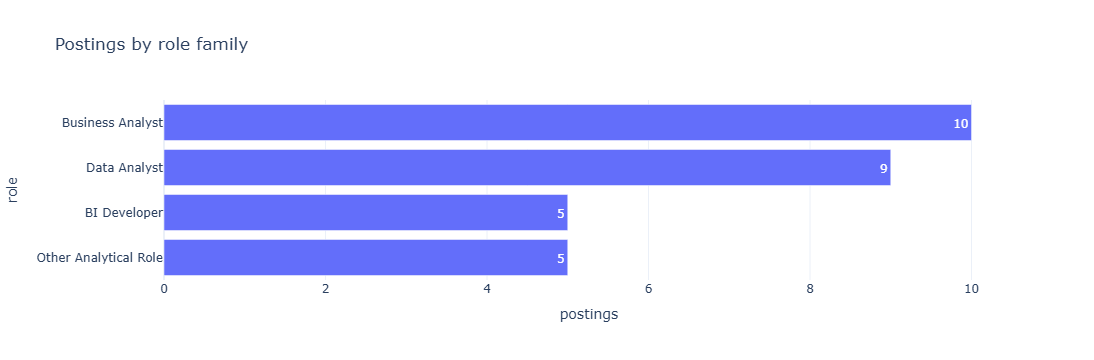

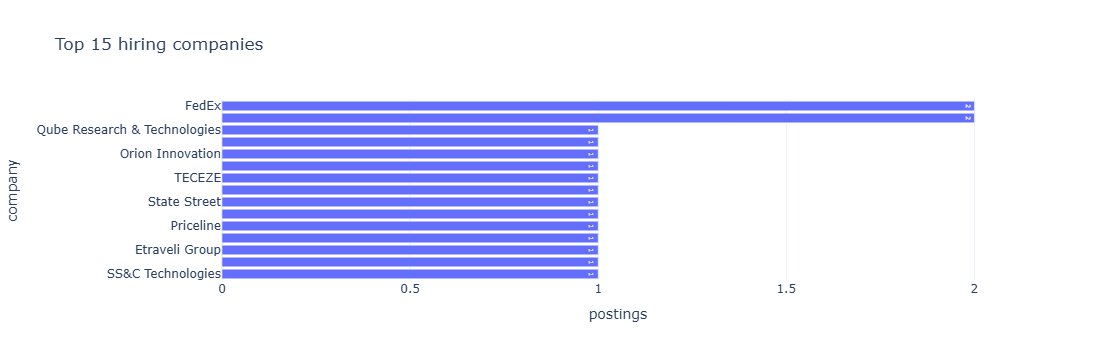


Titles classified as 'Other Analytical Role':


,postings
job_title,
Senior TSQL/ MSBI Developer,1
Data Consultant,1
"Analyst, Mobility Products",1
Custom Software Engineer,1
Business System Analyst MMH261030-8,1


In [14]:
fmt = lambda d: "n/a" if pd.isna(d) else d.strftime("%d %b %Y")
print(f"Postings              : {len(jobs)}")
print(f"With full description : {len(base)} ({len(base) / len(jobs):.0%})  <- skill statistics use only these")
print(f"Companies             : {jobs['company_name'].nunique()}")
print(f"Posted between        : {fmt(jobs['posted_date'].min())} and {fmt(jobs['posted_date'].max())}  "
      f"({int(jobs['posted_date'].isna().sum())} without a date)")

role_counts = jobs["standardized_role"].value_counts().rename_axis("role").reset_index(name="postings")
fig = px.bar(role_counts, x="postings", y="role", orientation="h", text="postings", title="Postings by role family")
fig.update_layout(yaxis={"categoryorder": "total ascending"}); show(fig)

top_co = jobs["company_name"].value_counts().head(15).rename_axis("company").reset_index(name="postings")
fig = px.bar(top_co, x="postings", y="company", orientation="h", text="postings", title="Top 15 hiring companies")
fig.update_layout(yaxis={"categoryorder": "total ascending"}); show(fig)

# Titles the role rules did not recognise: add keywords to ROLE_RULES in cleaner.py if you see a pattern
other = jobs.loc[jobs["standardized_role"] == "Other Analytical Role", "job_title"].value_counts().head(15)
print("\nTitles classified as 'Other Analytical Role':"); display(other.to_frame("postings"))

## 11. Skill demand

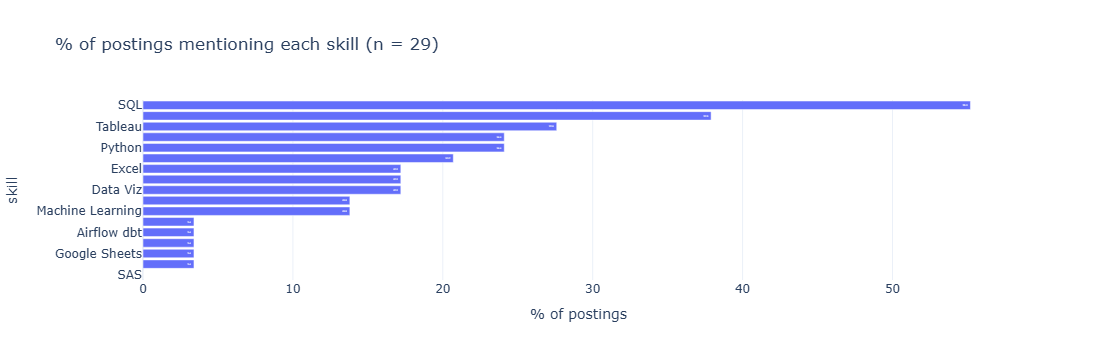

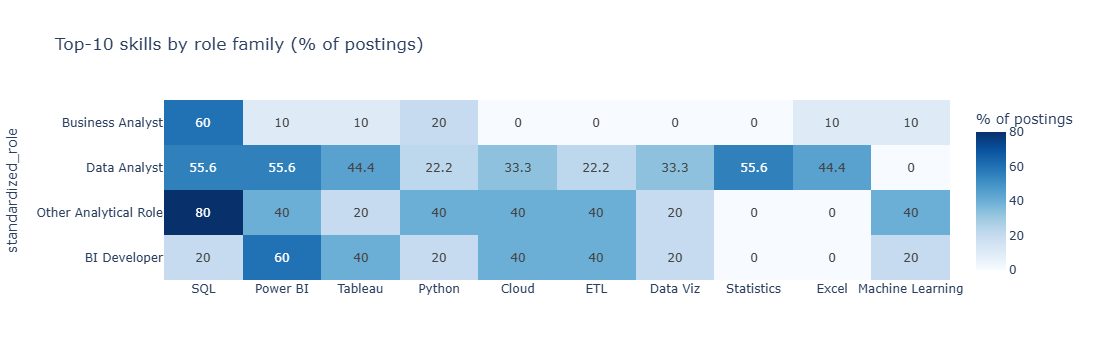

In [15]:
sd = analysis_utils.skill_demand(jobs)
fig = px.bar(sd, x="pct_of_jobs", y="skill", orientation="h", text="pct_of_jobs",
             title=f"% of postings mentioning each skill (n = {len(base)})", labels={"pct_of_jobs": "% of postings"})
fig.update_layout(yaxis={"categoryorder": "total ascending"}); show(fig)

# By role family (only roles with at least 3 postings)
counts = base["standardized_role"].value_counts()
by_role = analysis_utils.skill_demand(jobs, by="standardized_role")
by_role = by_role.loc[counts[counts >= 3].index, sd["skill"].head(10)]
fig = px.imshow(by_role, text_auto=True, aspect="auto", color_continuous_scale="Blues",
                labels=dict(color="% of postings"), title="Top-10 skills by role family (% of postings)")
show(fig)

## 12. Skill co-occurrence
Read each row as: *of the postings that ask for the row skill, what % also ask for the column skill?*

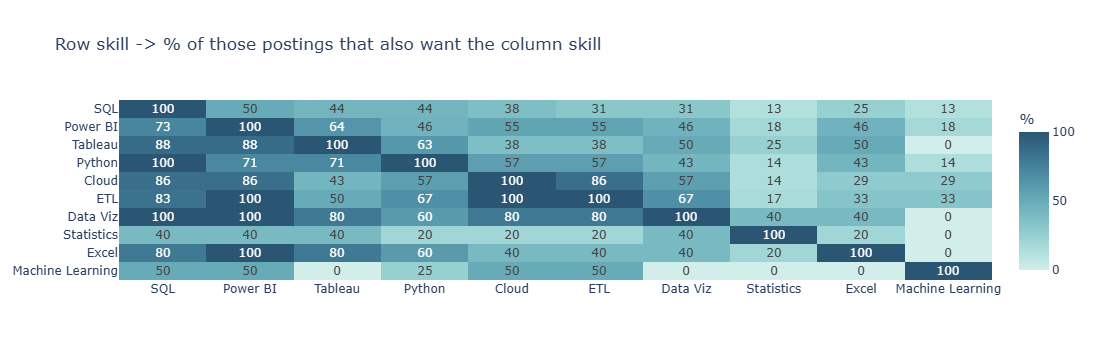

In [16]:
co_counts, co_pct = analysis_utils.skill_cooccurrence(jobs)
top = sd["skill"].head(10).tolist()
fig = px.imshow(co_pct.loc[top, top], text_auto=".0f", aspect="auto", color_continuous_scale="Teal",
                labels=dict(color="%"), title="Row skill -> % of those postings that also want the column skill")
show(fig)

## 13. Experience, seniority and entry-level roles

24 of 29 postings state a minimum experience (median 5 years). Regex-based: spot-check a few!


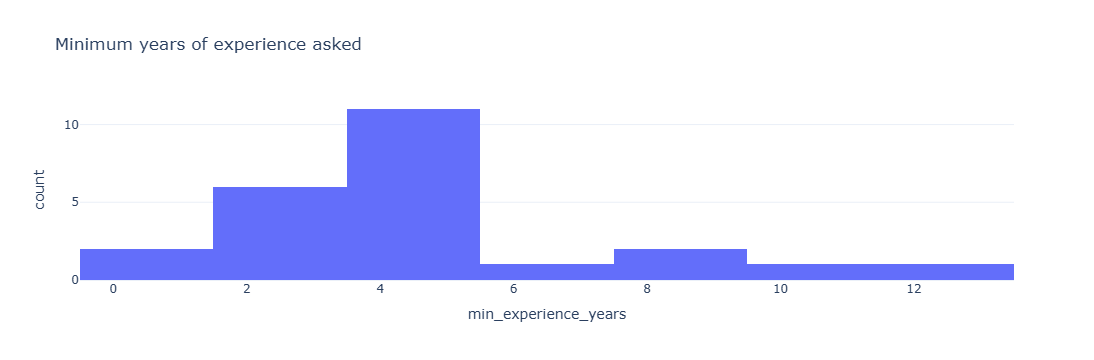

Entry-level friendly = 'fresher/entry level' in text, <= 1 year asked, or seniority Entry/Internship


,share,postings
standardized_role,,
Data Analyst,11.1,9
Business Analyst,10.0,10
BI Developer,0.0,5
Other Analytical Role,0.0,5


Fewer than 10 entry-level postings with descriptions: collect more data for this comparison.


In [17]:
has_exp = jobs.dropna(subset=["min_experience_years"])
print(f"{len(has_exp)} of {len(jobs)} postings state a minimum experience "
      f"(median {has_exp['min_experience_years'].median():.0f} years). Regex-based: spot-check a few!")
fig = px.histogram(has_exp, x="min_experience_years", nbins=12, title="Minimum years of experience asked")
show(fig)

entry = (jobs.groupby("standardized_role")["entry_level_friendly"].agg(share="mean", postings="size")
         .assign(share=lambda d: (d["share"] * 100).round(1)).sort_values("share", ascending=False))
print("Entry-level friendly = 'fresher/entry level' in text, <= 1 year asked, or seniority Entry/Internship")
display(entry)

entry_jobs = jobs[jobs["entry_level_friendly"]]
if len(analysis_utils.with_descriptions(entry_jobs)) >= 10:
    cmp = (analysis_utils.skill_demand(jobs)[["skill", "pct_of_jobs"]].rename(columns={"pct_of_jobs": "All postings"})
           .merge(analysis_utils.skill_demand(entry_jobs)[["skill", "pct_of_jobs"]]
                  .rename(columns={"pct_of_jobs": "Entry-level friendly"}), on="skill"))
    fig = px.bar(cmp.melt("skill", var_name="group", value_name="% of postings"), x="% of postings", y="skill",
                 color="group", barmode="group", orientation="h", title="Skills: all postings vs entry-level friendly")
    fig.update_layout(yaxis={"categoryorder": "total ascending"}); show(fig)
else:
    print("Fewer than 10 entry-level postings with descriptions: collect more data for this comparison.")

## 14. Skill-match score: how much of the market do *your* skills cover?

Your skills: Excel, SQL, Python, Power BI, Data Viz
Postings considered (description + at least one skill): 23
  - ask for at least one of your skills : 82.6%
  - ask ONLY for skills you already have: 26.1%


,skill,pct_of_jobs_asking,extra_fully_covered_pct_if_learned
0,Tableau,34.8,13.0
1,Statistics,21.7,13.0
2,Machine Learning,17.4,8.7
3,Cloud,30.4,4.3
4,Google Sheets,4.3,0.0
5,Looker,17.4,0.0
6,R,4.3,0.0
7,SAS,0.0,0.0


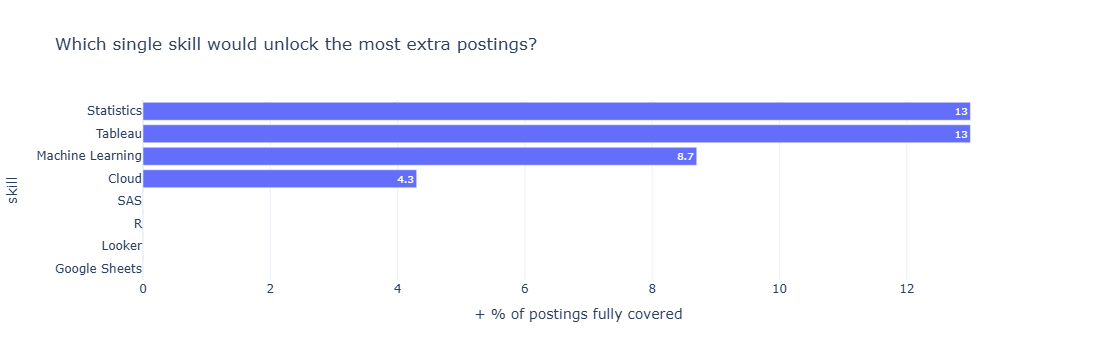

In [18]:
summary_match, gains = analysis_utils.skill_match(jobs, MY_SKILLS)
print("Your skills:", ", ".join(s.replace("_", " ") for s in MY_SKILLS))
print(f"Postings considered (description + at least one skill): {summary_match['postings_considered']}")
print(f"  - ask for at least one of your skills : {summary_match['pct_with_at_least_one_of_my_skills']}%")
print(f"  - ask ONLY for skills you already have: {summary_match['pct_fully_covered']}%")
display(gains.head(8))

fig = px.bar(gains.head(8), x="extra_fully_covered_pct_if_learned", y="skill", orientation="h",
             text="extra_fully_covered_pct_if_learned",
             title="Which single skill would unlock the most extra postings?",
             labels={"extra_fully_covered_pct_if_learned": "+ % of postings fully covered"})
fig.update_layout(yaxis={"categoryorder": "total ascending"}); show(fig)

## 15. Work mode, location and trend

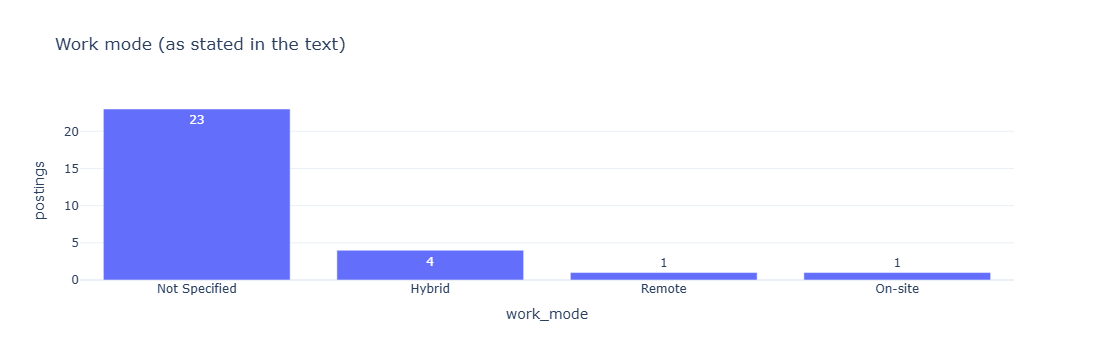

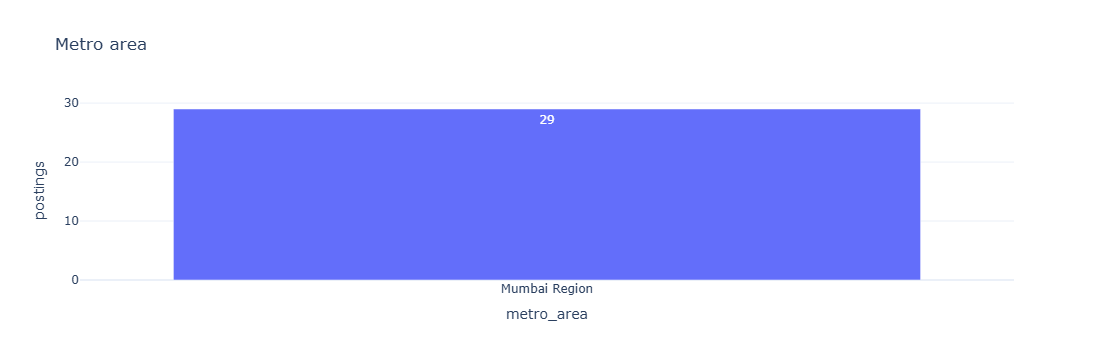

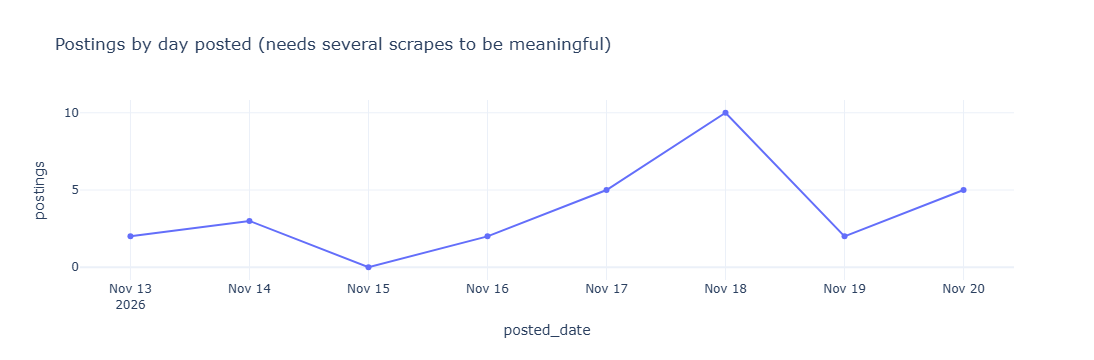

In [19]:
for col, title in [("work_mode", "Work mode (as stated in the text)"), ("metro_area", "Metro area")]:
    vc = jobs[col].value_counts().head(10).rename_axis(col).reset_index(name="postings")
    fig = px.bar(vc, x=col, y="postings", text="postings", title=title); show(fig)

dated = jobs.dropna(subset=["posted_date"])
if len(dated):
    span = (dated["posted_date"].max() - dated["posted_date"].min()).days
    freq = "W" if span > 60 else "D"
    trend = dated.set_index("posted_date").resample(freq).size().rename("postings").reset_index()
    fig = px.line(trend, x="posted_date", y="postings", markers=True,
                  title=f"Postings by {'week' if freq == 'W' else 'day'} posted (needs several scrapes to be meaningful)")
    show(fig)

## 16. Export for Power BI
Connect Power BI to the MySQL views directly (live), or use these CSVs. Relate `jobs` and `skills_long` on `job_id`.

In [20]:
config.EXPORT_DIR.mkdir(exist_ok=True)
jobs.drop(columns=["job_description"], errors="ignore").to_csv(config.EXPORT_DIR / "jobs.csv", index=False, encoding="utf-8-sig")
skills[["job_id", "skill"]].to_csv(config.EXPORT_DIR / "skills_long.csv", index=False, encoding="utf-8-sig")
analysis_utils.skill_demand(jobs, by="standardized_role").reset_index().to_csv(
    config.EXPORT_DIR / "skill_demand_by_role.csv", index=False, encoding="utf-8-sig")
print("Exported to", config.EXPORT_DIR, "->", sorted(p.name for p in config.EXPORT_DIR.glob("*.csv")))

Exported to C:\Users\Admin\Desktop\Data projects\New folder\linkedin-job-etl\powerbi_exports -> ['jobs.csv', 'skill_demand_by_role.csv', 'skills_long.csv']


## 17. Key findings (auto-generated from the data above)

In [21]:
print(f"Data: {source} | {len(jobs)} postings | {len(base)} with descriptions\n")
print("- Most requested skills :", ", ".join(f"{r.skill} ({r.pct_of_jobs:.0f}%)" for r in sd.head(4).itertuples()))
print(f"- Largest role family   : {role_counts.iloc[0]['role']} ({role_counts.iloc[0]['postings']} postings)")
print(f"- Entry-level friendly  : {jobs['entry_level_friendly'].mean():.0%} of all postings")
print(f"- Your skill coverage   : {summary_match['pct_fully_covered']}% of postings need nothing beyond {', '.join(s.replace('_', ' ') for s in MY_SKILLS)}")
if len(gains):
    b = gains.iloc[0]
    print(f"- Best next skill       : {b['skill']} (+{b['extra_fully_covered_pct_if_learned']} points of coverage, asked in {b['pct_of_jobs_asking']}% of postings)")

Data: database | 29 postings | 29 with descriptions

- Most requested skills : SQL (55%), Power BI (38%), Tableau (28%), Python (24%)
- Largest role family   : Business Analyst (10 postings)
- Entry-level friendly  : 7% of all postings
- Your skill coverage   : 26.1% of postings need nothing beyond Excel, SQL, Python, Power BI, Data Viz
- Best next skill       : Tableau (+13.0 points of coverage, asked in 34.8% of postings)


## Command-line equivalent
```bash
python main.py --pages 1 --keywords "Data Analyst" "SQL Developer"
python main.py --from-raw data_backups/raw_20261118_204441.csv     # re-clean without scraping
python main.py --no-db                                              # CSV only
```